In [3]:
import pandas as pd
import os

def load_and_preprocess_tracking_data(filepath: str, group_value: str, group_id_value: int) -> pd.DataFrame:
    
    # 1. Input Validation: Check if the file exists
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"The file specified by '{filepath}' does not exist. Please check the path!")
    if not os.path.isfile(filepath):
        raise FileNotFoundError(f"The path '{filepath}' is not a file. Please provide a valid file path.")

    print(f"Loading data from: {filepath}")

    # 2. Load Data using pandas
    # We'll try to infer the file type based on the extension.
    # CSV is very common, but we can extend this for others like Excel.
    try:
        if filepath.lower().endswith('.csv'):
            df = pd.read_csv(filepath)
        elif filepath.lower().endswith(('.xls', '.xlsx')):
            df = pd.read_excel(filepath)
        else:
            print("Couldn't infer file type from extension. Attempting to read as CSV by default.")
            df = pd.read_csv(filepath) # Default to CSV if extension is unknown
    except pd.errors.EmptyDataError:
        raise pd.errors.EmptyDataError(f"The file '{filepath}' is empty. No data to load!")
    except Exception as e:
        raise Exception(f"Encountered an error while loading the file '{filepath}': {e}")

    # 3. Define the columns we want to read and their new names
    original_columns = [
        'Center of the object_0',
        'Center of the object_1',
        'Center of the object_2',
        'timestep'
    ]
    new_column_names = {
        'Center of the object_0': 'x',
        'Center of the object_1': 'y',
        'Center of the object_2': 'z',
        'timestep': 't'
    }

    # 4. Check if all required columns exist in the loaded DataFrame
    missing_columns = [col for col in original_columns if col not in df.columns]
    if missing_columns:
        raise ValueError(
            f"The following required columns were not found in the file: {missing_columns}. "
            f"Available columns are: {df.columns.tolist()}"
        )

    # 5. Select and rename the specified columns
    # We select only the columns we need first to make the DataFrame smaller before copying.
    df_selected_and_renamed = df[original_columns].rename(columns=new_column_names)
    print(f"Renamed columns. Current columns: {df_selected_and_renamed.columns.tolist()}")

    # 6. Perform a deep copy
    # This is crucial! A deep copy ensures that 'processed_df' is a completely
    # independent DataFrame. If you modify 'processed_df', it will not affect
    # the original 'df' or any other references to the original data.
    processed_df = df_selected_and_renamed.copy(deep=True)

    # 7. Add the 'group' column
    # The value for this column comes directly from the 'group_value' parameter.
    processed_df['group'] = group_value
    processed_df['group_id'] = group_id_value

    return processed_df


In [4]:
filepath = "/workspaces/Cellular-TDA/data/Old Data/centroids control_table.csv"
group_value = "0"
group_id_value = 1
control_data = load_and_preprocess_tracking_data(filepath, group_value, group_id_value)

Loading data from: /workspaces/Cellular-TDA/data/Old Data/centroids control_table.csv
Renamed columns. Current columns: ['x', 'y', 'z', 't']


In [5]:
import gudhi as gd
import gudhi.representations
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
scaler                     = StandardScaler(); 
scaled_control_data        = scaler.fit_transform(control_data[["x","y","z"]])
rips_complex               = gd.RipsComplex(points=scaled_control_data, max_edge_length  = 2.0)
control_data_simplex_tree  = rips_complex.create_simplex_tree(max_dimension = 2)
control_data_digm          = control_data_simplex_tree.persistence()
control_data_intervals     = control_data_simplex_tree.persistence_intervals_in_dimension(1)
x_min, x_max               = control_data_intervals[:,0].min(), control_data_intervals[:,1].max()
LS                         = gd.representations.Landscape(resolution=100)
control_data_PL_vector_row = LS.fit_transform([control_data_intervals])


In [6]:
layers = control_data_PL_vector_row.reshape(5,100)

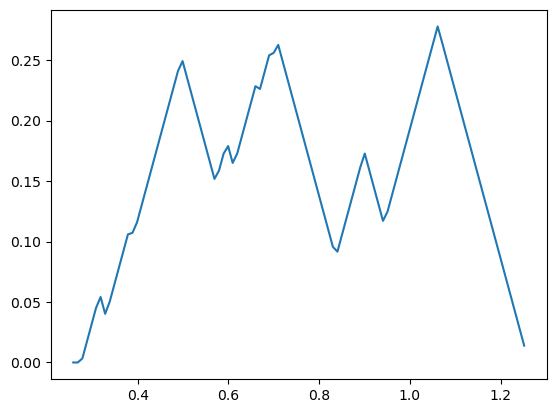

In [7]:
x_values = np.linspace( control_data_intervals[:,0].min(), control_data_intervals[:,1].max(), 100 )
plt.plot(x_values, layers[0][:,])